# Módulo 04 

### Notebook 1: Machine Learning y métricas

**Objetivos**
- Entender qué es "aprender" para un modelo y los tipos de aprendizaje.
- Dominar las métricas de **regresión** y **clasificación**: qué miden, cuándo usar cada una y cómo engañan.
- Reconocer el *overfitting* y el *underfitting*.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid")
SEMILLA = 42

---
## 1. ¿Qué es Machine Learning?

En la programación tradicional **tú escribes las reglas**. En Machine Learning **el modelo aprende las reglas a partir de ejemplos**.

```
 Programación tradicional:   Datos + Reglas      ──>  Respuestas
 Machine Learning:           Datos + Respuestas  ──>  Reglas (el modelo)
```

| Tipo | ¿Hay respuesta conocida (etiqueta)? | Tareas | Algoritmos |
|---|---|---|---|
| **Supervisado** | Sí | **Regresión** (número): precio, demanda | Regresión lineal, árboles, Random Forest, XGBoost, SVR |
| | | **Clasificación** (categoría): churn, fraude | Regresión logística, árboles, RF, XGBoost, KNN, SVM |
| **No supervisado** | No | **Clustering** (segmentar) | K-Means, DBSCAN, jerárquico |
| | | Reducción de dimensión | PCA, autoencoders |

---
## 2. Métricas de regresión

Tenemos los valores reales $y$ y los predichos $\hat{y}$. Una métrica resume **qué tan lejos** están.

In [2]:
reales = np.array([250_000, 300_000, 200_000, 400_000, 350_000])
predichos = np.array([240_000, 310_000, 210_000, 380_000, 340_000])
errores = reales - predichos
pd.DataFrame({"real": reales, "predicho": predichos, "error": errores, "error_abs": np.abs(errores)})

,real,predicho,error,error_abs
0,250000,240000,10000,10000
1,300000,310000,-10000,10000
2,200000,210000,-10000,10000
3,400000,380000,20000,20000
4,350000,340000,10000,10000


### MAE: error absoluto medio
$$MAE = \frac{1}{n}\sum |y_i - \hat{y}_i|$$
"En promedio me equivoco por **X** pesos". Está en las **mismas unidades** del target y es fácil de explicar.

### MSE y RMSE: error cuadrático (medio y su raíz)
$$MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE}$$
Al elevar al cuadrado, **castiga mucho los errores grandes**. El RMSE vuelve a las unidades del target.

### MAPE: error porcentual absoluto medio
$$MAPE = \frac{100}{n}\sum \left|\frac{y_i - \hat{y}_i}{y_i}\right|$$
"En promedio me equivoco un **X %**". Ideal para el negocio, pero **explota si hay valores reales cercanos a 0**.

### R²: coeficiente de determinación
$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
Qué proporción de la variabilidad explica el modelo **frente a predecir siempre el promedio**. 1 es perfecto, 0 es igual que el promedio y negativo es **peor** que el promedio.
e.g “el modelo elimina el x % del error que tendría si predijera siempre el promedio”. Es un modelo muy bueno.

In [3]:
print(f"MAE  = {mean_absolute_error(reales, predichos):>10,.0f}")
print(f"MSE  = {mean_squared_error(reales, predichos):>10,.0f}   ← en pesos² (difícil de interpretar)")
print(f"RMSE = {root_mean_squared_error(reales, predichos):>10,.0f}")
print(f"MAPE = {mean_absolute_percentage_error(reales, predichos) * 100:>10.2f} %")
print(f"R²   = {r2_score(reales, predichos):>10.3f}")

MAE  =     12,000
MSE  = 160,000,000   ← en pesos² (difícil de interpretar)
RMSE =     12,649
MAPE =       4.04 %
R²   =      0.968


| Métrica | Valor | Unidad | Cómo se lee |
|---|---|---|---|
| **MAE** | 12.000 | USD | En promedio, el modelo se equivoca en USD 12.000 por casa. |
| **MSE** | 160.000.000 | USD² | Promedio de los errores al cuadrado. No se interpreta directamente: es un paso para calcular el RMSE. |
| **RMSE** | 12.649 | USD | El error típico es de unos USD 12.649. Castiga más los errores grandes que el MAE. |
| **MAPE** | 4,04 % | % | En promedio, el modelo se equivoca en un 4 % del precio real. |
| **R²** | 0,968 | Sin unidad (0 a 1) | El modelo explica el 96,8 % de las diferencias de precio entre las casas. |

**Lectura conjunta:** el MAE y el RMSE son parecidos, así que los errores son parejos y no hay casos muy desviados. El MAPE muestra que USD 12.000 es poco frente al precio de las casas (4 %), y el R² confirma que el modelo es mucho mejor que predecir siempre el promedio.

### Experimento: ¿qué pasa con un solo error enorme?

In [4]:
predichos_con_error = predichos.copy()
predichos_con_error[3] = 200_000  # una predicción muy mala (real 400.000)

comparacion = pd.DataFrame(
    {
        "sin error grande": [mean_absolute_error(reales, predichos), root_mean_squared_error(reales, predichos)],
        "con 1 error grande": [mean_absolute_error(reales, predichos_con_error), root_mean_squared_error(reales, predichos_con_error)],
    },
    index=["MAE", "RMSE"],
)
comparacion["aumento"] = (comparacion.iloc[:, 1] / comparacion.iloc[:, 0]).round(1).astype(str) + "×"
comparacion

,sin error grande,con 1 error grande,aumento
MAE,12000.000000,48000.000000,4.0×
RMSE,12649.110641,89888.820217,7.1×


El RMSE crece mucho más que el MAE: **el RMSE es sensible a los errores grandes**.

| Métrica | Úsala cuando… |
|---|---|
| **MAE** | Quieres un error "típico" fácil de explicar y robusto a *outliers* |
| **RMSE** | Los errores grandes son especialmente graves (p.ej. quedarte sin inventario) |
| **MAPE** | El negocio piensa en porcentajes y el target nunca es cercano a 0 |
| **R²** | Comparar modelos sobre el mismo dataset (no sirve para comparar entre datasets) |

---
## 3. Métricas de clasificación

**Caso:** detectar si un tumor es **maligno** a partir de 30 medidas de una imagen (dataset *Breast Cancer Wisconsin*, incluido en scikit-learn).

Definimos **positivo (1) = maligno**, que es lo que queremos detectar.

In [5]:
datos = load_breast_cancer(as_frame=True)
X = datos.data
y = 1 - datos.target  # en el dataset original 1 = benigno; lo invertimos para que 1 = maligno
print(X.shape, "· % de malignos:", round(y.mean() * 100, 1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEMILLA, stratify=y)
clasificador = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clasificador.fit(X_train, y_train)
y_pred = clasificador.predict(X_test)
y_prob = clasificador.predict_proba(X_test)[:, 1]  # probabilidad de ser maligno

(569, 30) · % de malignos: 37.3


> `stratify=y` mantiene la misma proporción de malignos en train y test. Úsalo **siempre** en clasificación.

### 3.1 Matriz de confusión

|  | Predicho: benigno (0) | Predicho: maligno (1) |
|---|:---:|:---:|
| **Real: benigno (0)** | TN | FP (falsa alarma) |
| **Real: maligno (1)** | FN (¡se nos escapó!) | TP |

Nuestra clase positiva es cuando es maligno, porque la clasificación se para detectar cuando es malo, por ende cuando es maligno etiqueta 1, y cuando no es maligno o sea que es benigno, etiqueta 0. 

Por ende los verdaderos positivos (TP): Son esos casos cuando el modelo predijo que era maligno y en realidad era maligno: 60 casos

Verdaderos negativos (TN): son los casos cuando el modelo dice que no son malignos o sea benignos y en realidad era beningnos: 106 casos

Falso negativo (FN): son los casos que el modelo predijo que eran benignos pero en realidad es maligno: 4 casos

Falso positivo (FP): son los casos que el modelo dijo que era maligno pero en realidad es benigno: 1 caso


¿Para una aplicación médica qué es más grave? decirle a un paciente que tiene cáncer cuando no lo tiene (FP) o decirle que no tiene cáncer cuando en realidad si lo tiene (FN) y el cáncer silencioso podría terminar con su vida? 

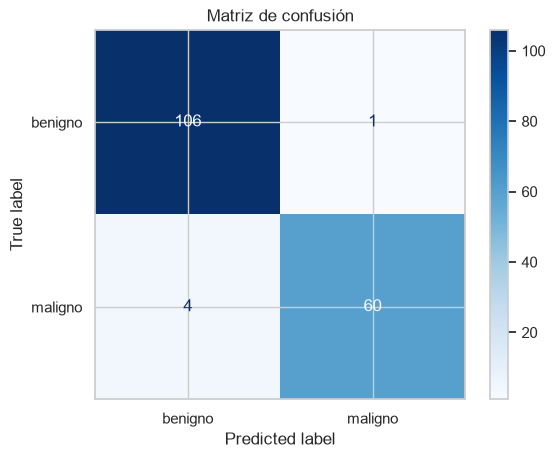

TN=106  FP=1  FN=4  TP=60


In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["benigno", "maligno"], cmap="Blues")
plt.title("Matriz de confusión")
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### 3.2 Las métricas, una por una

| Métrica | Fórmula | Pregunta que responde | Importa cuando… |
|---|---|---|---|
| **Accuracy** | (TP+TN) / total | ¿Qué % acerté en total? | Clases balanceadas |
| **Precision** | TP / (TP+FP) | De los que dije "maligno", ¿cuántos lo eran? | Las **falsas alarmas** son caras (spam que esconde un correo importante) |
| **Recall** | TP / (TP+FN) | De los malignos reales, ¿cuántos detecté? | **Que se escape un positivo** es grave (cáncer, fraude, ciberataques) |
| **F1** | 2·P·R / (P+R) | Balance entre precision y recall | Clases desbalanceadas |
| **AUC-ROC** | Área bajo la curva ROC | ¿Qué tan bien **ordena** de más a menos riesgoso? | Comparar modelos sin fijar un umbral |

In [7]:
print(f"Accuracy  = {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision = {precision_score(y_test, y_pred):.3f}")
print(f"Recall    = {recall_score(y_test, y_pred):.3f}")
print(f"F1        = {f1_score(y_test, y_pred):.3f}")
print(f"AUC-ROC   = {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["benigno", "maligno"]))

Accuracy  = 0.971
Precision = 0.984
Recall    = 0.938
F1        = 0.960
AUC-ROC   = 0.998

              precision    recall  f1-score   support

     benigno       0.96      0.99      0.98       107
     maligno       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### 3.3 Curva ROC

La ROC grafica la **tasa de verdaderos positivos** (recall) contra la **tasa de falsos positivos** para **todos** los umbrales posibles.
- AUC = 0.5 → igual que lanzar una moneda
- AUC = 1 → separa perfecto

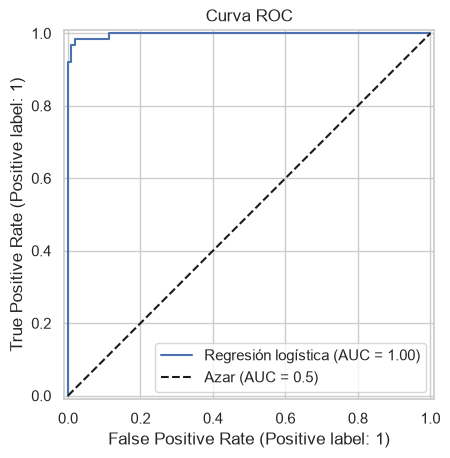

In [8]:
RocCurveDisplay.from_predictions(y_test, y_prob, name="Regresión logística")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
plt.legend()
plt.title("Curva ROC")
plt.show()

Eje vertical, True Positive Rate: de los malignos reales, ¿qué porcentaje detecta? Es el recall. Arriba es mejor.

Eje horizontal, False Positive Rate: de los benignos reales, ¿qué porcentaje marca por error como malignos? Son las falsas alarmas. A la izquierda es mejor.

La curva ROC muestra que el modelo separa casi perfectamente los tumores malignos de los benignos: su AUC es prácticamente 1. Pero eso no garantiza cero errores: con el umbral de 0,5, igual se escapan 4 malignos. La ROC nos dice que el modelo es bueno; la matriz de confusión nos ayuda a elegir el umbral. Y si en su proyecto ven un AUC tan alto, revisen que no haya data leakage.

### 3.4 El umbral es una decisión de negocio

`predict()` usa un umbral de **0.5**: si P(maligno) ≥ 0.5 → maligno. Pero en medicina **preferimos más falsas alarmas a dejar escapar un cáncer**. Bajemos el umbral:

In [9]:
filas = []
for umbral in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (y_prob >= umbral).astype(int)
    filas.append(
        {
            "umbral": umbral,
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "malignos_que_se_escapan (FN)": int(((pred == 0) & (y_test == 1)).sum()),
        }
    )
pd.DataFrame(filas).round(3)

,umbral,precision,recall,f1,malignos_que_se_escapan (FN)
0,0.1,0.900,0.984,0.940,1
1,0.3,0.984,0.969,0.976,2
2,0.5,0.984,0.938,0.960,4
3,0.7,1.000,0.922,0.959,5
4,0.9,1.000,0.797,0.887,13


**Umbral bajo** → más recall y menos precision. **Umbral alto** → al revés. No hay un umbral "correcto": depende de **cuánto cuesta cada error** en el negocio.

### 3.5 La paradoja de la accuracy

Imagina un dataset de fraude con **99 % de transacciones legítimas**. Un "modelo" que **siempre** dice "no es fraude"…

In [10]:
y_fraude = np.array([0] * 990 + [1] * 10)
siempre_no = np.zeros_like(y_fraude)
print(f"Accuracy = {accuracy_score(y_fraude, siempre_no):.1%}  ← ¡parece excelente!")
print(f"Recall   = {recall_score(y_fraude, siempre_no):.1%}  ← no detecta NI UN fraude")

Accuracy = 99.0%  ← ¡parece excelente!
Recall   = 0.0%  ← no detecta NI UN fraude


**Moraleja:** con clases desbalanceadas, **nunca** reportes solo la accuracy.

---
## 4. *Underfitting* y *overfitting*

Un buen modelo **aprende los patrones** del entrenamiento **y generaliza** a datos nuevos.

| | *Underfitting* (subajuste) | Buen ajuste | *Overfitting* (sobreajuste) |
|---|---|---|---|
| Analogía | No estudió | Entendió el tema | Memorizó las respuestas del taller |
| Error en train | Alto | Bajo | **Muy** bajo |
| Error en test | Alto | Bajo | **Alto** |
| Causa | Modelo muy simple | — | Modelo muy complejo o pocos datos |

### Experimento: polinomios de distinto grado

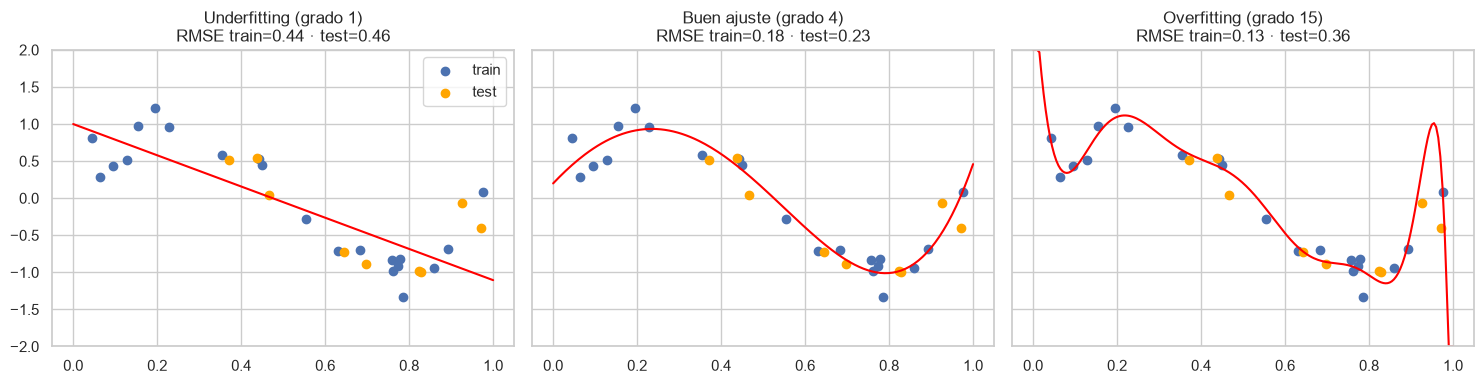

In [11]:
rng = np.random.default_rng(SEMILLA)
x = np.sort(rng.uniform(0, 1, 30))
y_ruido = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, size=x.size)
x_tr, x_te, y_tr, y_te = train_test_split(x.reshape(-1, 1), y_ruido, test_size=0.3, random_state=SEMILLA)
x_grilla = np.linspace(0, 1, 200).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, grado, nombre in zip(axes, [1, 4, 15], ["Underfitting", "Buen ajuste", "Overfitting"]):
    modelo = make_pipeline(PolynomialFeatures(grado), LinearRegression()).fit(x_tr, y_tr)
    rmse_tr = root_mean_squared_error(y_tr, modelo.predict(x_tr))
    rmse_te = root_mean_squared_error(y_te, modelo.predict(x_te))
    ax.scatter(x_tr, y_tr, label="train")
    ax.scatter(x_te, y_te, color="orange", label="test")
    ax.plot(x_grilla, np.clip(modelo.predict(x_grilla), -2, 2), color="red")
    ax.set(title=f"{nombre} (grado {grado})\nRMSE train={rmse_tr:.2f} · test={rmse_te:.2f}", ylim=(-2, 2))
axes[0].legend()
plt.tight_layout()
plt.show()

- **Underfitting**: el modelo “no estudió”. Una recta no puede seguir la forma de onda de los datos. Se equivoca mucho en train y mucho en test (0,44 y 0,46). El problema no es de generalización: el modelo ni siquiera aprendió los datos de entrenamiento. Qué hacer: mejorar el modelo o mejorar las variables.

- **Overfitting**: La curva se retuerce para pasar por cada punto azul, y en los bordes se dispara hacia arriba y hacia abajo de forma absurda. Tiene el menor error en train (0,13), pero en test el error sube a 0,36. Aprendió hasta el ruido de los datos de entrenamiento, y eso no le sirve con datos nuevos. Qué hacer: hace falta un modelo más simple, más datos o regularización.




### Curva de complejidad

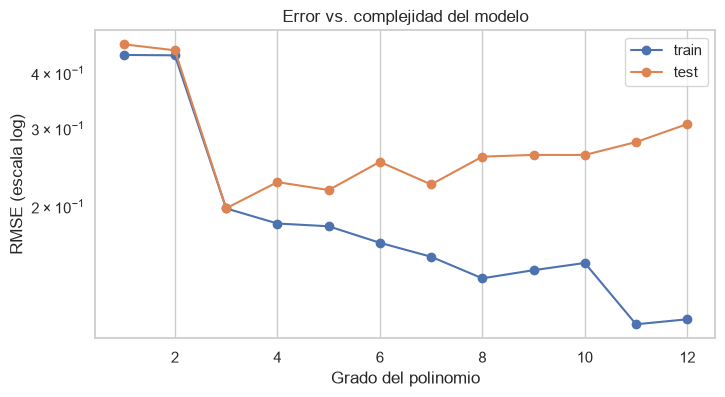

In [12]:
grados = range(1, 13)
curva = []
for grado in grados:
    modelo = make_pipeline(PolynomialFeatures(grado), LinearRegression()).fit(x_tr, y_tr)
    curva.append((root_mean_squared_error(y_tr, modelo.predict(x_tr)), root_mean_squared_error(y_te, modelo.predict(x_te))))
curva = pd.DataFrame(curva, columns=["train", "test"], index=grados)

ax = curva.plot(marker="o", figsize=(8, 4), logy=True)
ax.set(title="Error vs. complejidad del modelo", xlabel="Grado del polinomio", ylabel="RMSE (escala log)")
plt.show()

**El error de train tiende a bajar** al aumentar la complejidad. **El de test baja y después sube.** El mejor modelo está en el "valle" del error de test.

A medida que el modelo se vuelve más complejo, siempre mejora con los datos que ya vio: la línea azul baja. Pero con datos nuevos mejora solo hasta cierto punto, y después empeora: la línea naranja sube. Ese punto, donde el error en test es mínimo, es el modelo que debemos elegir. Cuando las dos líneas se separan mucho, el modelo está memorizando.


### ¿Cómo atacarlos?

| Reducir *underfitting* | Reducir *overfitting* |
|---|---|
| Modelo más complejo | Más datos de entrenamiento |
| Más o mejores variables (*feature engineering*) | Modelo más simple (menos profundidad, menos variables) |
| Limpiar el ruido de los datos | **Regularización**: Ridge ($+\lambda\sum w^2$), Lasso ($+\lambda\sum \lvert w \rvert$) |
| Entrenar más tiempo (redes) | *Early stopping*, *dropout* (redes) |
| | **Validación cruzada** para elegir hiperparámetros |

---
## Ejercicios guiados (15 min)

1. **Calcula a mano** (con NumPy, sin scikit-learn) el MAE, el RMSE y el R² de `reales` y `predichos`, y compáralos con los de la sección 2.
2. **Umbral de negocio:** en el caso del cáncer, ¿qué umbral elegirías si la regla es "no se puede escapar más de 1 maligno"? ¿Cuántas falsas alarmas genera?
3. **Regularización:** repite el experimento del polinomio de grado 15 cambiando `LinearRegression()` por `Ridge(alpha=0.001)`. ¿Qué pasa con el RMSE de test?

Soluciones en `ejercicios/soluciones/solucion_01_metricas.py`.

In [13]:
# Tu código aquí